# TitleGuard: Online Title Similarity Verification
### SIH1782 · Third Internal Data Science Project

**Question:** Does a proposed publication title resemble an existing title closely enough to require review?

In [128]:
# Install only missing runtime requirements; no GPU or external model download.
import importlib.util, subprocess, sys
packages = {'numpy':'numpy>=1.26,<3', 'pandas':'pandas>=2.1,<3',
            'scipy':'scipy>=1.11,<2', 'sklearn':'scikit-learn>=1.4,<2',
            'matplotlib':'matplotlib>=3.8,<4', 'ipywidgets':'ipywidgets>=8.1,<9'}
missing = [spec for module, spec in packages.items() if importlib.util.find_spec(module) is None]
if missing: subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
import os
os.environ.setdefault('MPLCONFIGDIR', '/tmp/titleguard-matplotlib')
import matplotlib.pyplot as plt
from IPython.display import display, clear_output
print('CPU runtime ready.')

CPU runtime ready.


## 1. Import, clean and inspect data


### Core implementation — where the project actually works

| Function | Responsibility |
|---|---|
| `normalize()` | Unicode, punctuation, case and input validation |
| `features()` | Five numerical comparisons between two titles |
| `TitleVerifier.__init__()` | Word/character TF-IDF registry index |
| `fit_pairs()` | Train logistic regression on training pairs |
| `search()` | Weighted cosine retrieval, classification and review decisions |
| `explain()` | Show the evidence and classifier contribution for one candidate |
| `make_pairs()` / `evaluate()` (Section 3) | Family split, validation threshold, held-out metrics |

In [129]:
"""Explainable retrieval and pair classification for educational title screening."""
import re
import unicodedata
from difflib import SequenceMatcher
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics.pairwise import cosine_similarity


def normalize(text):
    if not isinstance(text, str):
        raise ValueError("Title must be text.")
    text = unicodedata.normalize("NFKC", text).casefold()
    text = " ".join(re.findall(r"[^\W_]+", text, flags=re.UNICODE))
    if not text:
        raise ValueError("Enter a title containing letters or numbers.")
    if len(text) > 500:
        raise ValueError("Title must contain at most 500 normalized characters.")
    return text


def features(a, b):
    """Symmetric pair features; no fitted vocabulary or registry labels required."""
    a, b = normalize(a), normalize(b)
    x, y = set(a.split()), set(b.split())
    grams = lambda s: set(s[i:i+3] for i in range(max(1, len(s)-2)))
    u, v = grams(a), grams(b)
    return [float(a == b), len(x & y)/len(x | y),
            SequenceMatcher(None, a, b, autojunk=False).ratio(),
            min(len(a), len(b))/max(len(a), len(b)), len(u & v)/len(u | v)]


class TitleVerifier:
    def __init__(self, registry):
        required = {"title_id", "title"}
        if not required.issubset(registry.columns):
            raise ValueError("Registry requires title_id and title columns.")
        if registry.empty or registry.title_id.isna().any() or registry.title_id.duplicated().any():
            raise ValueError("Registry needs nonempty, unique title IDs.")
        self.registry = registry.copy().reset_index(drop=True)
        self.normalized = self.registry.title.map(normalize)
        if self.normalized.duplicated().any():
            raise ValueError("Registry contains duplicate normalized titles; clean it first.")
        self.word = TfidfVectorizer(ngram_range=(1, 2), token_pattern=r"(?u)\b\w+\b")
        self.char = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5))
        self.w = self.word.fit_transform(self.normalized)
        self.c = self.char.fit_transform(self.normalized)
        self.model = None
        self.threshold = 0.5

    def fit_pairs(self, pairs):
        if not {0, 1}.issubset(set(pairs.label)):
            raise ValueError("Training needs both positive and negative pairs.")
        self.model = LogisticRegression(class_weight="balanced", random_state=42, max_iter=1000)
        self.model.fit([features(a, b) for a, b in zip(pairs["query"], pairs.candidate)], pairs.label)
        return self

    def pair_scores(self, pairs):
        if self.model is None:
            raise RuntimeError("Train the pair classifier first.")
        return self.model.predict_proba([features(a, b) for a, b in zip(pairs["query"], pairs.candidate)])[:, 1]

    def search(self, title, top_k=5):
        q = normalize(title)
        if not isinstance(top_k, int) or top_k < 1:
            raise ValueError("top_k must be a positive integer.")
        score = .4*cosine_similarity(self.word.transform([q]), self.w)[0] + .6*cosine_similarity(self.char.transform([q]), self.c)[0]
        ids = np.argsort(-score, kind="stable")[:top_k]
        # Always prioritize normalized exact matches, even for a registry with tied scores.
        exact_ids = np.flatnonzero(self.normalized.to_numpy() == q)
        ids = list(dict.fromkeys([*exact_ids, *ids]))[:top_k]
        out = self.registry.iloc[ids].copy()
        out["similarity"] = score[ids]
        out["exact_match"] = self.normalized.iloc[ids].to_numpy() == q
        if self.model is not None:
            out["pair_score"] = self.model.predict_proba([features(q, t) for t in out.title])[:, 1]
            out["decision"] = ["EXACT MATCH" if e else "REVIEW" if p >= self.threshold else "LOW SIMILARITY" for e, p in zip(out.exact_match, out.pair_score)]
        else:
            out["decision"] = np.where(out.exact_match, "EXACT MATCH", "REVIEW (UNTRAINED)")
        return out.reset_index(drop=True)

    def explain(self, query, candidate):
        """Local logistic evidence; contributions sum to the log-odds margin."""
        if self.model is None:
            raise RuntimeError('Train the pair classifier first.')
        names = ['Normalized equality', 'Token Jaccard', 'Sequence similarity', 'Length ratio', 'Trigram Jaccard']
        values = np.array(features(query, candidate))
        contributions = values * self.model.coef_[0]
        table = pd.DataFrame({'feature': names, 'value': values,
                              'weight': self.model.coef_[0], 'log_odds_contribution': contributions})
        margin = float(contributions.sum() + self.model.intercept_[0])
        score = float(self.model.predict_proba([values])[0, 1])
        shared = sorted(set(normalize(query).split()) & set(normalize(candidate).split()))
        return table, {'shared_tokens': shared, 'intercept': float(self.model.intercept_[0]),
                       'log_odds': margin, 'pair_score': score, 'threshold': self.threshold}


In [130]:

from pathlib import Path
from io import BytesIO

# Always ask the user to upload registry.csv.
try:
    from google.colab import files
except ImportError as exc:
    raise FileNotFoundError(
        'Upload registry.csv in Google Colab before running this cell.'
    ) from exc

print('Choose the registry.csv file downloaded from this repository.')
uploaded = files.upload()

if len(uploaded) != 1:
    raise ValueError('Upload exactly one CSV dataset, then rerun this cell.')

filename, contents = next(iter(uploaded.items()))

if not filename.lower().endswith('.csv'):
    raise ValueError('Select a CSV file, then rerun this cell.')

raw = pd.read_csv(BytesIO(contents))

required_columns = {'title_id', 'title', 'category', 'family', 'source'}
if not required_columns.issubset(raw.columns):
    raise ValueError(
        'Use the supplied registry.csv. Missing columns: '
        + ', '.join(sorted(required_columns - set(raw.columns)))
    )

print('Raw shape:', raw.shape)
display(raw.isna().sum().rename('missing'))

registry = raw.dropna(
    subset=['title_id', 'title', 'category', 'family']
).copy()

registry['normalized'] = registry.title.map(normalize)
registry = registry.drop_duplicates(
    'normalized'
).sort_values('title_id').reset_index(drop=True)

if registry.title_id.duplicated().any():
    raise ValueError('Each title_id must be unique.')

if registry.family.nunique() < 24:
    raise ValueError(
        'The included family-held-out benchmark needs at least 24 families. '
        'Use the supplied registry.csv.'
    )

registry['word_count'] = registry.normalized.str.split().str.len()
registry['length'] = registry.normalized.str.len()

display(registry.head())

display(
    registry.groupby('category')
    .agg(
        titles=('title_id', 'count'),
        mean_length=('length', 'mean')
    )
    .sort_values('mean_length', ascending=False)
)


Choose the registry.csv file downloaded from this repository.


Saving registry.csv to registry (4).csv
Raw shape: (72, 5)


,missing
title_id,0
title,0
category,0
family,0
source,0


,title_id,title,category,family,source,normalized,word_count,length
0,T001,The River Chronicle,Chronicle,river,synthetic educational example,the river chronicle,3,19
1,T002,The River Herald,Herald,river,synthetic educational example,the river herald,3,16
2,T003,The River Review,Review,river,synthetic educational example,the river review,3,16
3,T004,The City Chronicle,Chronicle,city,synthetic educational example,the city chronicle,3,18
4,T005,The City Herald,Herald,city,synthetic educational example,the city herald,3,15


,titles,mean_length
category,,
Chronicle,24,21.291667
Herald,24,18.291667
Review,24,18.291667


## 2. Exploratory data analysis and descriptive statistics

,length,word_count
count,72.000000,72.0
mean,19.291667,3.0
median,19.000000,3.0
var,5.448944,0.0
std,2.334297,0.0
min,15.000000,3.0
max,25.000000,3.0


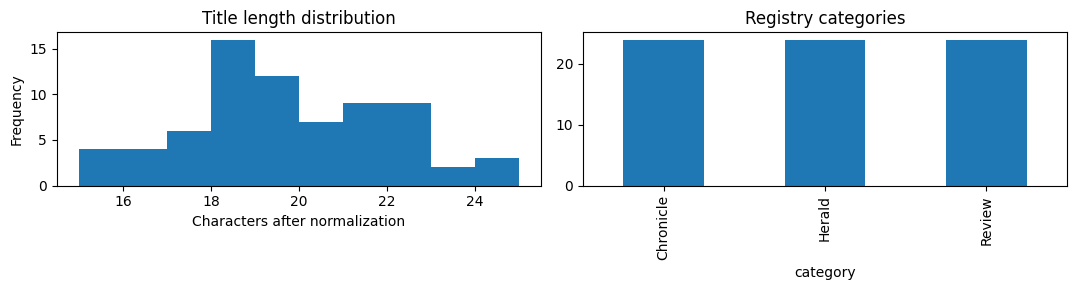

Length/word-count correlation:


,length,word_count
length,1.0,NaN
word_count,NaN,NaN


In [131]:
display(registry[['length','word_count']].agg(['count','mean','median','var','std','min','max']))
fig, ax = plt.subplots(1, 2, figsize=(11, 3))
registry.length.plot.hist(bins=10, ax=ax[0], title='Title length distribution')
ax[0].set_xlabel('Characters after normalization')
registry.category.value_counts().plot.bar(ax=ax[1], title='Registry categories')
plt.tight_layout(); plt.show()
# Word count is constant in this template dataset: its correlation is undefined.
print('Length/word-count correlation:')
display(registry[['length','word_count']].corr())

## 3. Models and evaluation design


In [132]:
"""Reproducible family-held-out benchmark with validation-only threshold tuning."""
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix



def make_pairs(registry):
    families = registry.family.unique().copy()
    np.random.default_rng(42).shuffle(families)
    partitions = {"train":families[:14], "validation":families[14:19], "test":families[19:]}
    rows = []
    for split, groups in partitions.items():
        subset = registry[registry.family.isin(groups)].reset_index(drop=True)
        for i, row in subset.iterrows():
            title = row.title
            words = title.split()
            variants = [title.upper()+'!', ' '.join(words[1:]), ' '.join(words[::-1]), title[:-2]+title[-1]+title[-2]]
            for query in variants:
                rows.append([query, title, 1, row.family, split, row.title_id])
            # Hard negatives share the subject; easy negatives share the format.
            hard = subset[(subset.family == row.family) & (subset.title_id != row.title_id)].iloc[0]
            easy = subset[(subset.family != row.family) & (subset.category == row.category)].iloc[0]
            for negative in [hard, easy]:
                rows.append([title, negative.title, 0, row.family, split, negative.title_id])
    return pd.DataFrame(rows, columns=['query','candidate','label','family','split','candidate_id'])


def evaluate(verifier, pairs):
    train, val, test = [pairs[pairs.split == s].copy() for s in ['train','validation','test']]
    verifier.fit_pairs(train)
    scores = verifier.pair_scores(val)
    grid = np.linspace(.05, .95, 91)
    # Tie break toward a higher threshold. Validation data only.
    threshold = max(grid, key=lambda t: (f1_score(val.label, scores >= t, zero_division=0), t))
    verifier.threshold = float(threshold)
    pred = verifier.pair_scores(test) >= threshold
    metrics = {'threshold':float(threshold), 'test_pairs':len(test),
               'accuracy':accuracy_score(test.label,pred), 'precision':precision_score(test.label,pred,zero_division=0),
               'recall':recall_score(test.label,pred,zero_division=0), 'f1':f1_score(test.label,pred,zero_division=0),
               'confusion_matrix':confusion_matrix(test.label,pred,labels=[0,1]).tolist()}
    # Retrieval evaluated on positive test queries, against the full registry.
    positives = test[test.label == 1]
    ranks = []
    for row in positives.itertuples():
        found = verifier.search(row.query, top_k=5).title_id.tolist()
        ranks.append(found.index(row.candidate_id)+1 if row.candidate_id in found else 0)
    metrics['recall_at_5'] = float(np.mean(np.array(ranks)>0))
    metrics['mrr_at_5'] = float(np.mean([1/x if x else 0 for x in ranks]))
    test['pair_score'] = verifier.pair_scores(test)
    test['prediction'] = pred.astype(int)
    return metrics, test

label,different,same title
split,,
test,30,60
train,84,168
validation,30,60


,Held-out result
threshold,0.750000
test_pairs,90.000000
accuracy,0.933333
precision,1.000000
recall,0.900000
f1,0.947368
recall_at_5,1.000000
mrr_at_5,1.000000


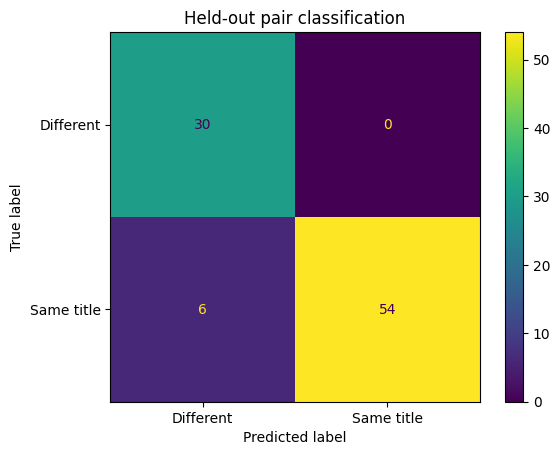

Held-out errors: 6


,query,candidate,label,family,split,candidate_id,pair_score,prediction
349,City Herald,The City Herald,1,city,test,T005,0.699265,0
350,Herald City The,The City Herald,1,city,test,T005,0.648887,0
351,The City Heradl,The City Herald,1,city,test,T005,0.713422,0
355,City Review,The City Review,1,city,test,T006,0.699265,0
356,Review City The,The City Review,1,city,test,T006,0.648887,0
357,The City Reviwe,The City Review,1,city,test,T006,0.713422,0


Token-Jaccard baseline test F1: 0.667
Measured results apply only to this synthetic benchmark.


In [133]:
pairs = make_pairs(registry)
display(pd.crosstab(pairs.split, pairs.label).rename(columns={0:'different',1:'same title'}))
verifier = TitleVerifier(registry)
metrics, test_predictions = evaluate(verifier, pairs)
display(pd.Series({k:v for k,v in metrics.items() if k != 'confusion_matrix'}, name='Held-out result'))
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay(np.array(metrics['confusion_matrix']), display_labels=['Different','Same title']).plot()
plt.title('Held-out pair classification'); plt.show()
errors = test_predictions[test_predictions.label != test_predictions.prediction]
print('Held-out errors:', len(errors))
display(errors if len(errors) else test_predictions.head())
# Compare with a fixed token-Jaccard baseline on the same test set.
from sklearn.metrics import f1_score
baseline = [features(a,b)[1] >= .8 for a,b in zip(test_predictions["query"],test_predictions.candidate)]
print('Token-Jaccard baseline test F1:', round(f1_score(test_predictions.label,baseline), 3))
print('Measured results apply only to this synthetic benchmark.')

### 3.1 Model comparison, threshold sensitivity and error audit
We compare the same held-out pairs using logistic regression, a shallow decision tree and KNN. Each review threshold is chosen on **validation F1 only**. Test results are reported once for comparison, not used to change the main model. The fixed Jaccard baseline above remains a simple reference.

,model,validation_threshold,test_accuracy,test_precision,test_recall,test_f1
0,Logistic regression (main),0.75,0.9333,1.0,0.9,0.9474
1,Decision tree (depth 4),0.95,1.0000,1.0,1.0,1.0000
2,KNN (k=5),0.95,1.0000,1.0,1.0,1.0000


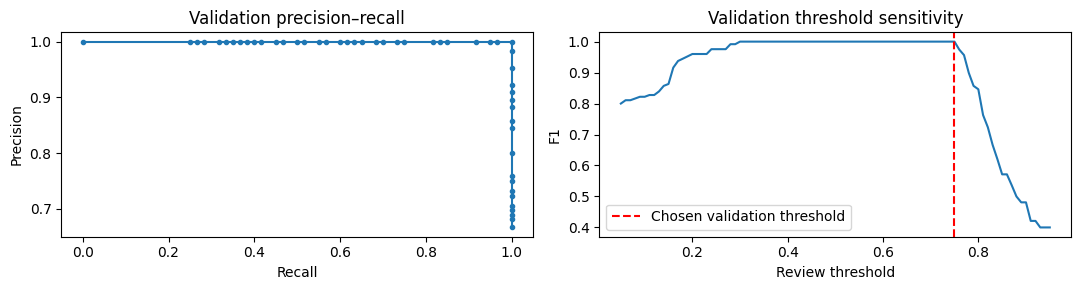

Every held-out error:


,query,candidate,label,pair_score,prediction,error_type
349,City Herald,The City Herald,1,0.699265,0,Missed conflict
350,Herald City The,The City Herald,1,0.648887,0,Missed conflict
351,The City Heradl,The City Herald,1,0.713422,0,Missed conflict
355,City Review,The City Review,1,0.699265,0,Missed conflict
356,Review City The,The City Review,1,0.648887,0,Missed conflict
357,The City Reviwe,The City Review,1,0.713422,0,Missed conflict


Use this audit to propose future improvements; do not tune on these test examples.


In [134]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, precision_recall_curve

train_pairs, validation_pairs, heldout_pairs = [pairs[pairs.split == split] for split in ['train','validation','test']]
def pair_matrix(frame):
    return np.array([features(a,b) for a,b in zip(frame['query'], frame.candidate)])
X_train, X_val, X_test = map(pair_matrix, [train_pairs, validation_pairs, heldout_pairs])
comparisons = []
for name, model in [
    ('Logistic regression (main)', verifier.model),
    ('Decision tree (depth 4)', DecisionTreeClassifier(max_depth=4, min_samples_leaf=5, random_state=42)),
    ('KNN (k=5)', KNeighborsClassifier(n_neighbors=5))]:
    if model is not verifier.model:
        model.fit(X_train, train_pairs.label)
    val_scores = model.predict_proba(X_val)[:,1]
    threshold = max(np.linspace(.05,.95,91), key=lambda t:(f1_score(validation_pairs.label, val_scores >= t, zero_division=0), t))
    predicted = model.predict_proba(X_test)[:,1] >= threshold
    comparisons.append({'model':name,'validation_threshold':threshold,
                        'test_accuracy':accuracy_score(heldout_pairs.label,predicted),
                        'test_precision':precision_score(heldout_pairs.label,predicted,zero_division=0),
                        'test_recall':recall_score(heldout_pairs.label,predicted,zero_division=0),
                        'test_f1':f1_score(heldout_pairs.label,predicted,zero_division=0)})
display(pd.DataFrame(comparisons).round(4))
val_scores = verifier.pair_scores(validation_pairs)
precision, recall, _ = precision_recall_curve(validation_pairs.label, val_scores)
fig, axes = plt.subplots(1,2,figsize=(11,3))
axes[0].plot(recall, precision, marker='.')
axes[0].set(xlabel='Recall', ylabel='Precision', title='Validation precision–recall')
threshold_grid = np.linspace(.05,.95,91)
axes[1].plot(threshold_grid,[f1_score(validation_pairs.label,val_scores>=t,zero_division=0) for t in threshold_grid])
axes[1].axvline(verifier.threshold, color='red', linestyle='--',label='Chosen validation threshold')
axes[1].set(xlabel='Review threshold',ylabel='F1',title='Validation threshold sensitivity')
axes[1].legend(); plt.tight_layout(); plt.show()
print('Every held-out error:')
audit = test_predictions[test_predictions.label != test_predictions.prediction].copy()
audit['error_type'] = np.where(audit.label == 1, 'Missed conflict', 'Unnecessary review')
display(audit[['query','candidate','label','pair_score','prediction','error_type']])
print('Use this audit to propose future improvements; do not tune on these test examples.')

## 4. Statistical inference
**H₀:** Mean token Jaccard similarity is equal for positive and negative title pairs.

**H₁:** The means differ. We compare one average per family and class on training data, reducing repeated-pair dependence. Welch's test is exploratory: only 14 synthetic training families exist; generated labels and templates violate assumptions needed for population claims. A small p-value is not evidence of production readiness.

The bootstrap below resamples whole held-out families for an approximate F1 interval. It reflects this benchmark only; five test families are too few for strong uncertainty claims.

In [135]:

from scipy.stats import ttest_ind
import numpy as np

training = pairs[pairs.split == 'train'].copy()

training['jaccard'] = [
    features(a, b)[1]
    for a, b in zip(training['query'], training['candidate'])
]

family_means = (
    training.groupby(['family', 'label'])['jaccard']
    .mean()
    .unstack()
)

print("Family-level token Jaccard means:")
display(family_means)

if 0 not in family_means.columns or 1 not in family_means.columns:
    print("Welch's test cannot be performed: one label group is missing.")
elif (
    len(family_means[0].dropna()) < 2
    or len(family_means[1].dropna()) < 2
    or family_means[0].var() == 0
    or family_means[1].var() == 0
):
    print(
        "Welch's test is not reliable here: insufficient family-level "
        "variation or too few independent family observations."
    )
else:
    stat, p = ttest_ind(
        family_means[1].dropna(),
        family_means[0].dropna(),
        equal_var=False
    )
    print(f"Exploratory Welch's t-test: t={stat:.3f}, p={p:.5g}")

# Bootstrap by resampling whole held-out families.
rng = np.random.default_rng(42)
family_ids = test_predictions['family'].unique()

if len(family_ids) < 2:
    print("Too few held-out families to estimate a useful bootstrap interval.")
else:
    boot = []

    for _ in range(2000):
        sampled_ids = rng.choice(
            family_ids,
            size=len(family_ids),
            replace=True
        )

        sample = pd.concat([
            test_predictions[test_predictions.family == family]
            for family in sampled_ids
        ], ignore_index=True)

        boot.append(
            f1_score(
                sample['label'],
                sample['prediction'],
                zero_division=0
            )
        )

    lower, upper = np.quantile(boot, [0.025, 0.975])

    print(f"Held-out families: {len(family_ids)}")
    print(f"Observed test F1: {f1_score(test_predictions['label'], test_predictions['prediction'], zero_division=0):.4f}")
    print(f"Approximate family-bootstrap 95% interval: [{lower:.4f}, {upper:.4f}]")

    if len(family_ids) < 10:
        print(
            "Caution: only five families are available. "
            "The bootstrap interval is highly uncertain and should be "
            "treated as descriptive, not as strong evidence of generalization."
        )


Family-level token Jaccard means:


label,0,1
family,,
agriculture,0.5,0.791667
arts,0.5,0.791667
business,0.5,0.791667
coastal,0.5,0.791667
community,0.5,0.791667
culture,0.5,0.791667
education,0.5,0.791667
health,0.5,0.791667
metro,0.5,0.791667


Welch's test is not reliable here: insufficient family-level variation or too few independent family observations.
Held-out families: 5
Observed test F1: 0.9474
Approximate family-bootstrap 95% interval: [0.8235, 1.0000]
Caution: only five families are available. The bootstrap interval is highly uncertain and should be treated as descriptive, not as strong evidence of generalization.


## 5. Unsupervised exploration
K-means groups registry titles by lexical content. Clusters are exploratory and do not determine title availability. Category labels are not used during clustering.

In [136]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
clusters = KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(verifier.w)
print('Cosine silhouette:', round(silhouette_score(verifier.w, clusters, metric='cosine'), 3))
display(pd.crosstab(pd.Series(clusters, name='cluster'), registry.category))

Cosine silhouette: 0.053


category,Chronicle,Herald,Review
cluster,,,
0,22,22,0
1,1,1,1
2,1,1,23


## 6. Interactive online submission demo
Enter a proposed title and press **Verify title**. Try `THE RIVER CHRONICLE!`, `River Chroncile`, and a new unrelated title. The form runs inside the Colab browser session; it is not a deployed multi-user service. Submitted text is processed in memory and is not stored or sent to an external API. Review the five candidates, rather than relying on a single label.

In [137]:
import ipywidgets as widgets
try:
    from google.colab import output
    output.enable_custom_widget_manager()
except ImportError:
    pass
entry = widgets.Text(value='River Chroncile', description='New title:', layout=widgets.Layout(width='80%'))
button = widgets.Button(description='Verify title', button_style='primary')
output_area = widgets.Output()
def verify_clicked(_):
    with output_area:
        clear_output(wait=True)
        try:
            matches = verifier.search(entry.value)
            decision = 'EXACT MATCH FOUND' if matches.exact_match.any() else 'HUMAN REVIEW RECOMMENDED' if (matches.decision == 'REVIEW').any() else 'NO STRONG MATCH FOUND — NOT AN APPROVAL'
            print(decision)
            display(matches[['title_id','title','similarity','pair_score','decision']].round(3))
            print('Similarity and pair scores are not calibrated approval probabilities.')
            best = matches.iloc[0]
            evidence, details = verifier.explain(entry.value, best.title)
            print('Why the top candidate was returned:', best.title)
            print('Shared words:', ', '.join(details['shared_tokens']) or '(none)')
            display(evidence.round(4))
            print(f"Classifier intercept: {details['intercept']:.3f}; log-odds: {details['log_odds']:.3f}; review threshold: {details['threshold']:.2f}")
            print('Contributions explain the pair classifier, not the separate TF-IDF retrieval score.')
            print('An exact normalized match overrides the classifier decision.')
        except ValueError as exc:
            print(str(exc))
button.on_click(verify_clicked)
display(widgets.VBox([entry, button, output_area]))
verify_clicked(None)

### 6.1 Batch checker and downloadable results


In [138]:

# 6.1 Batch checker and downloadable results

from pathlib import Path
import base64
import pandas as pd
import ipywidgets as widgets
from IPython.display import display, clear_output, HTML


# ---------- Batch checking logic ----------

def check_batch(frame):
    if frame is None or not isinstance(frame, pd.DataFrame):
        raise ValueError("Please provide a valid CSV dataset.")

    # Accept either a fresh input CSV or a previous results CSV.
    if 'title' not in frame.columns:
        if 'submitted_title' in frame.columns:
            frame = frame.rename(columns={'submitted_title': 'title'})
        else:
            raise ValueError(
                "CSV must contain a 'title' or 'submitted_title' column."
            )

    if frame.empty or len(frame) > 1000:
        raise ValueError("CSV must contain between 1 and 1,000 rows.")

    records = []

    for row_number, title in enumerate(frame['title'], start=1):
        try:
            if pd.isna(title) or not str(title).strip():
                raise ValueError("Title is empty.")

            title = str(title).strip()
            matches = verifier.search(title)

            if matches is None or matches.empty:
                raise ValueError("No candidate titles were returned.")

            exact = matches[matches['exact_match'] == True]
            flagged = matches[matches['decision'] == 'REVIEW']

            if not exact.empty:
                best = exact.iloc[0]
                decision = 'EXACT MATCH'

            elif not flagged.empty:
                best = flagged.sort_values(
                    'pair_score', ascending=False
                ).iloc[0]
                decision = 'REVIEW'

            else:
                best = matches.iloc[0]
                decision = 'LOW SIMILARITY — NOT APPROVAL'

            records.append({
                'row': row_number,
                'submitted_title': title,
                'matched_title': best['title'],
                'similarity': float(best['similarity']),
                'pair_score': float(best['pair_score']),
                'decision': decision,
                'error': ''
            })

        except Exception as exc:
            records.append({
                'row': row_number,
                'submitted_title': str(title),
                'matched_title': '',
                'similarity': None,
                'pair_score': None,
                'decision': 'INVALID INPUT',
                'error': str(exc)
            })

    return pd.DataFrame(records)


# ---------- Interface ----------

# Upload the CSV through Colab's Files panel first.
# Edit this path if your uploaded file has a different name.
csv_path_input = widgets.Text(
    value='/content/title_check_results.csv',
    description='CSV path:',
    placeholder='/content/your_file.csv',
    layout=widgets.Layout(width='95%'),
    style={'description_width': 'initial'}
)

batch_button = widgets.Button(
    description='Check CSV',
    button_style='primary'
)

example_button = widgets.Button(
    description='Check registry examples'
)

download_button = widgets.Button(
    description='Download results',
    disabled=True
)

batch_output = widgets.Output()
batch_state = {}


# ---------- Run and display results ----------

def run_batch(frame):
    results = check_batch(frame)

    batch_state['results'] = results
    download_button.disabled = False

    display(results.round(4))
    display(
        results['decision']
        .value_counts()
        .rename('count')
    )

    print(
        'Note: exact-match examples test input handling, '
        'not independent model accuracy.'
    )

    return results


# ---------- Check a CSV file ----------

def batch_clicked(_):
    with batch_output:
        clear_output(wait=True)
        batch_state.clear()
        download_button.disabled = True

        try:
            path = Path(csv_path_input.value.strip())

            if not path.is_file():
                raise FileNotFoundError(
                    f"File not found: {path}. "
                    "Upload the CSV using Colab's Files panel "
                    "and enter its correct path."
                )

            if path.suffix.lower() != '.csv':
                raise ValueError("Please select a .csv file.")

            if path.stat().st_size > 2_000_000:
                raise ValueError("CSV must be smaller than 2 MB.")

            frame = pd.read_csv(path)
            run_batch(frame)

        except (
            FileNotFoundError,
            ValueError,
            pd.errors.ParserError,
            UnicodeError,
            OSError
        ) as exc:
            print("Cannot check CSV:", str(exc))


# ---------- Check registry examples ----------

def examples_clicked(_):
    with batch_output:
        clear_output(wait=True)
        batch_state.clear()
        download_button.disabled = True

        try:
            if 'title' not in registry.columns:
                raise ValueError(
                    "The registry dataset has no 'title' column."
                )

            examples = registry[['title']].head(5)

            if examples.empty:
                raise ValueError("No registry examples are available.")

            run_batch(examples)

        except (ValueError, KeyError) as exc:
            print("Cannot check registry examples:", str(exc))


# ---------- Download results ----------

def download_clicked(_):
    with batch_output:
        if 'results' not in batch_state:
            print("Run a CSV check or registry examples first.")
            return

        export = batch_state['results'].copy()

        # Prevent spreadsheet formula injection in text fields.
        def safe_cell(value):
            if (
                isinstance(value, str)
                and value.lstrip().startswith(('=', '+', '-', '@'))
            ):
                return "'" + value
            return value

        for column in export.select_dtypes(
            include=['object']
        ).columns:
            export[column] = export[column].map(safe_cell)

        encoded = base64.b64encode(
            export.to_csv(index=False).encode('utf-8')
        ).decode('ascii')

        display(HTML(
            '<a download="title_check_results.csv" '
            'href="data:text/csv;base64,' + encoded + '">'
            'Download title_check_results.csv</a>'
        ))


# ---------- Connect buttons and display interface ----------

batch_button.on_click(batch_clicked)
example_button.on_click(examples_clicked)
download_button.on_click(download_clicked)

display(widgets.VBox([
    widgets.HTML(
        "<b>Batch checker and downloadable results</b>"
        "<p>Upload your CSV through Colab's Files panel, "
        "then enter its path below.</p>"
    ),
    csv_path_input,
    widgets.HBox([
        batch_button,
        example_button,
        download_button
    ]),
    batch_output
]))


### 6.2 Executable integrity checks
These checks validate software behavior, not model accuracy: exact matching, invalid inputs, family isolation, local explanations, batch error handling, and deterministic rankings. They run every time you select Run all.

In [139]:
def run_integrity_checks():
    count = 0
    first = registry.iloc[0].title
    assert verifier.search(first.upper()+'!').iloc[0].decision == 'EXACT MATCH'; count += 1
    for invalid in ['', '!!!', None, float('nan'), 'x'*501]:
        try:
            verifier.search(invalid)
        except ValueError:
            count += 1
        else:
            raise AssertionError('Invalid input accepted')
    groups = [set(pairs[pairs.split==s].family) for s in ['train','validation','test']]
    assert not (groups[0]&groups[1] or groups[1]&groups[2] or groups[0]&groups[2]); count += 1
    family_by_id = registry.set_index('title_id').family
    for split, split_groups in zip(['train','validation','test'], groups):
        assert set(family_by_id.loc[pairs[pairs.split==split].candidate_id]).issubset(split_groups)
    count += 1
    explanation, detail = verifier.explain('River Chroncile', 'The River Chronicle')
    assert np.isclose(explanation.log_odds_contribution.sum()+detail['intercept'],detail['log_odds'])
    assert np.isclose(1/(1+np.exp(-detail['log_odds'])),detail['pair_score']); count += 1
    batch = check_batch(pd.DataFrame({'title':[first,'!!!',None]}))
    assert batch.decision.tolist() == ['EXACT MATCH','INVALID INPUT','INVALID INPUT']; count += 1
    try:
        check_batch(pd.DataFrame({'wrong':['a']}))
    except ValueError:
        count += 1
    else:
        raise AssertionError('Missing batch title column accepted')
    assert verifier.search('River Chroncile').equals(verifier.search('River Chroncile')); count += 1
    assert len(verifier.search(first,1000)) == len(registry); count += 1
    print(f'{count} integrity checks passed. These are separate from the held-out accuracy estimate.')
run_integrity_checks()

13 integrity checks passed. These are separate from the held-out accuracy estimate.


6.3 Visual Analytics Dashboard

## Title Verification — Visual Analytics

Summary of the latest batch-checking results. These metrics describe this batch, not independent model accuracy.

,Metric,Value
0,Titles processed,5.0
1,Exact matches,5.0
2,Sent for review,0.0
3,Low similarity,0.0
4,Invalid inputs,0.0
5,Mean similarity,1.0


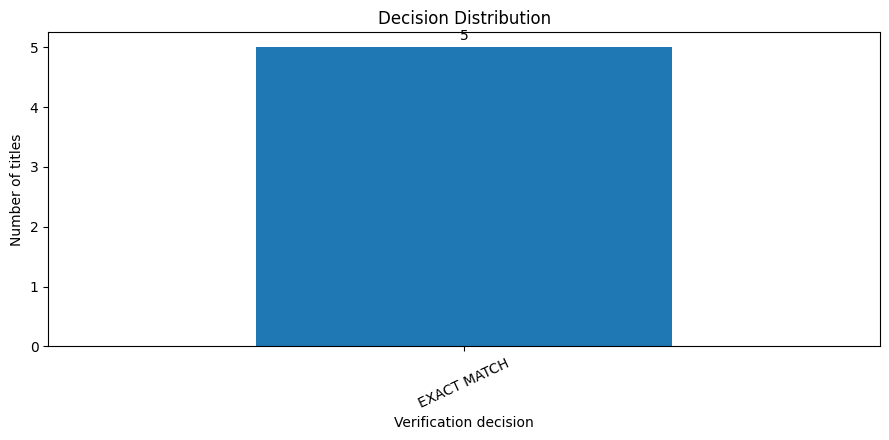

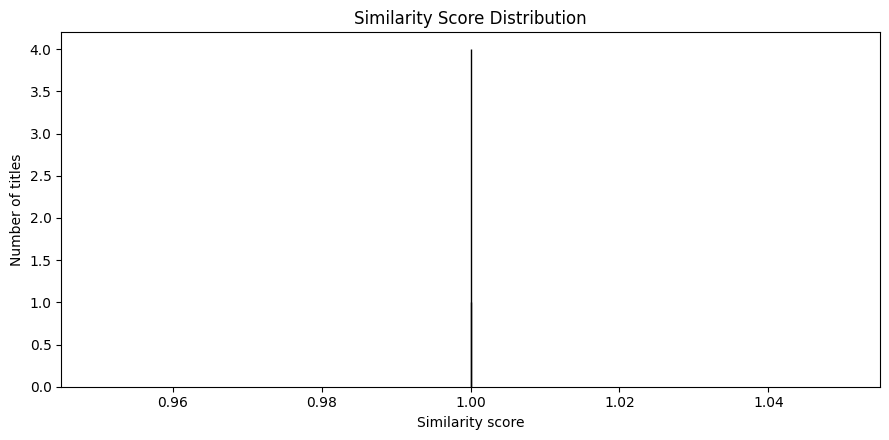

### Batch Summary

Total titles processed: 5
Exact-match rate: 100.0%
Review rate: 0.0%
Mean similarity: 1.0000
All titles received the same decision in this batch. Try a varied set of titles to examine more decision categories.


In [141]:

# 6.3 Visual Analytics Dashboard

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Use the actual results from Section 6.1
if 'batch_state' not in globals() or 'results' not in batch_state:
    raise ValueError(
        "Run Section 6.1 first using Check CSV or "
        "Check registry examples, then run this dashboard."
    )

results = batch_state['results'].copy()

if results.empty:
    raise ValueError("No results are available to visualize.")

# Normalize decision labels for consistent reporting
results['decision'] = results['decision'].fillna('UNKNOWN')
decision_counts = results['decision'].value_counts()

valid_scores = pd.to_numeric(
    results['similarity'], errors='coerce'
).dropna()

total = len(results)
exact = int((results['decision'] == 'EXACT MATCH').sum())
review = int((results['decision'] == 'REVIEW').sum())
low_similarity = int(
    (results['decision'] == 'LOW SIMILARITY — NOT APPROVAL').sum()
)
invalid = int((results['decision'] == 'INVALID INPUT').sum())

display(Markdown("## Title Verification — Visual Analytics"))
display(Markdown(
    "Summary of the latest batch-checking results. "
    "These metrics describe this batch, not independent model accuracy."
))

# Summary metrics
summary = pd.DataFrame({
    'Metric': [
        'Titles processed',
        'Exact matches',
        'Sent for review',
        'Low similarity',
        'Invalid inputs',
        'Mean similarity'
    ],
    'Value': [
        total,
        exact,
        review,
        low_similarity,
        invalid,
        round(valid_scores.mean(), 4) if not valid_scores.empty else 'N/A'
    ]
})

display(summary)

# Chart 1: Decision distribution
fig, ax = plt.subplots(figsize=(9, 4.5))
decision_counts.plot(kind='bar', ax=ax)
ax.set_title('Decision Distribution')
ax.set_xlabel('Verification decision')
ax.set_ylabel('Number of titles')
ax.tick_params(axis='x', rotation=25)

for container in ax.containers:
    ax.bar_label(container, fmt='%g', padding=3)

plt.tight_layout()
plt.show()

# Chart 2: Similarity score distribution
if not valid_scores.empty:
    fig, ax = plt.subplots(figsize=(9, 4.5))

    bins = min(10, max(1, valid_scores.nunique()))
    ax.hist(valid_scores, bins=bins, edgecolor='black')

    ax.set_title('Similarity Score Distribution')
    ax.set_xlabel('Similarity score')
    ax.set_ylabel('Number of titles')

    plt.tight_layout()
    plt.show()
else:
    print("No valid similarity scores are available to plot.")

# Short, data-driven interpretation
display(Markdown("### Batch Summary"))

print(f"Total titles processed: {total}")
print(f"Exact-match rate: {exact / total:.1%}")
print(f"Review rate: {review / total:.1%}")
print(
    "Mean similarity:",
    f"{valid_scores.mean():.4f}" if not valid_scores.empty else "N/A"
)

if results['decision'].nunique() == 1:
    print(
        "All titles received the same decision in this batch. "
        "Try a varied set of titles to examine more decision categories."
    )
